<a href="https://colab.research.google.com/github/ananyaj2201-dot/sales-data-analysis-and-business-insights-/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vivek468/superstore-dataset-final")

print("Path to dataset files:", path)

100%|██████████| 550k/550k [00:00<00:00, 54.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/vivek468/superstore-dataset-final/versions/1


In [2]:
import os

print(os.listdir(path))

['Sample - Superstore.csv']


In [3]:
import pandas as pd

file_path = path + "/Sample - Superstore.csv"

df = pd.read_csv(file_path, encoding="latin1")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
print("Shape:", df.shape)
print(df.columns.tolist())

Shape: (9994, 21)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [5]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.dtypes

,0
Row ID,int64
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


In [8]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

df.dtypes

,0
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


In [9]:
print("Order Date range:", df["Order Date"].min(), "to", df["Order Date"].max())
print("Ship Date range:", df["Ship Date"].min(), "to", df["Ship Date"].max())

Order Date range: 2014-01-03 00:00:00 to 2017-12-30 00:00:00
Ship Date range: 2014-01-07 00:00:00 to 2018-01-05 00:00:00


In [10]:
print("Total Sales:", df["Sales"].sum())
print("Total Profit:", df["Profit"].sum())
print("Total Quantity Sold:", df["Quantity"].sum())
print("Number of Orders:", df["Order ID"].nunique())
print("Number of Products:", df["Product ID"].nunique())

Total Sales: 2297200.8603000003
Total Profit: 286397.0217
Total Quantity Sold: 37873
Number of Orders: 5009
Number of Products: 1862


In [11]:
df["Year"] = df["Order Date"].dt.year

yearly_sales = df.groupby("Year")["Sales"].sum()

print(yearly_sales)

Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64


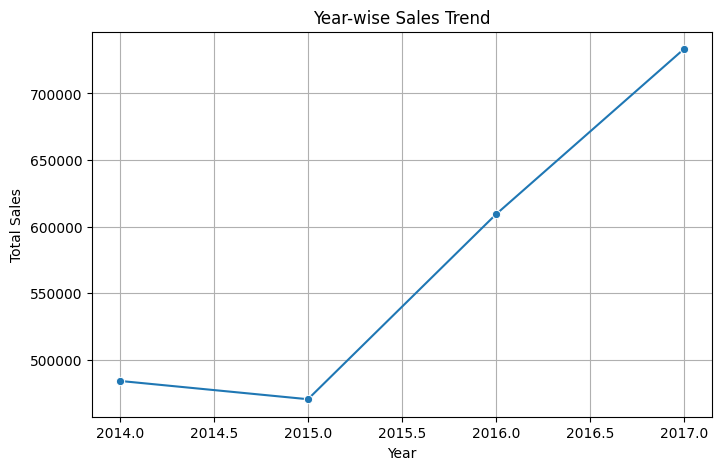

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.lineplot(
    x=yearly_sales.index,
    y=yearly_sales.values,
    marker="o"
)

plt.title("Year-wise Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.grid(True)

plt.show()

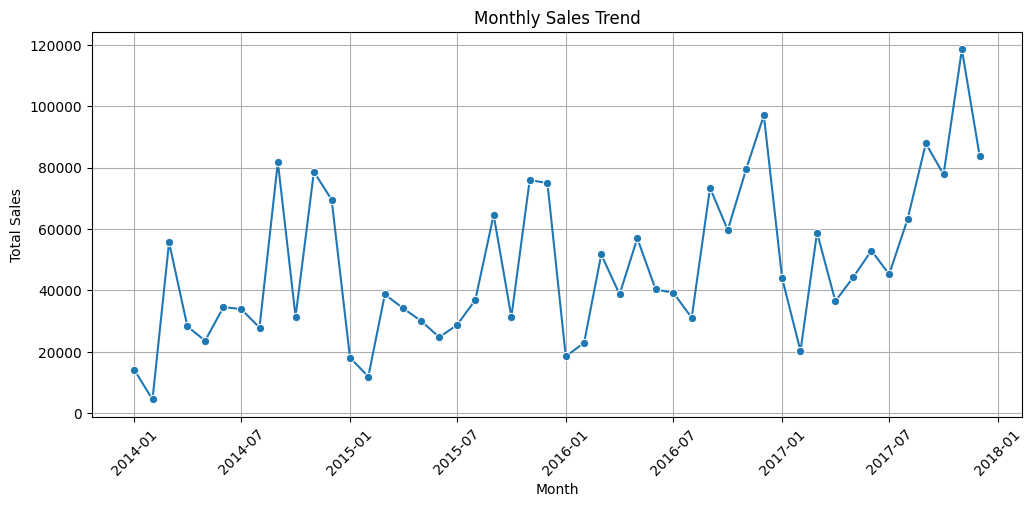

In [13]:
monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
)

monthly_sales.index = monthly_sales.index.to_timestamp()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [14]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

print(category_sales)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


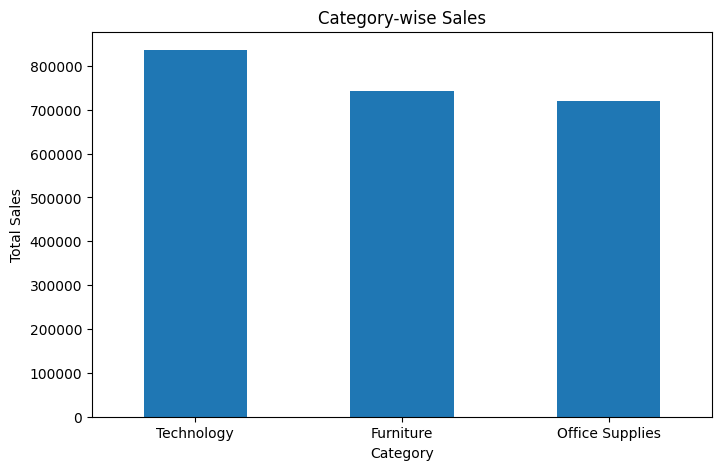

In [15]:
import matplotlib.pyplot as plt

category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
category_sales.plot(kind="bar")
plt.title("Category-wise Sales")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

In [16]:
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False)

print(subcategory_sales)

Sub-Category
Phones         330007.0540
Chairs         328449.1030
Storage        223843.6080
Tables         206965.5320
Binders        203412.7330
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91705.1640
Paper           78479.2060
Supplies        46673.5380
Art             27118.7920
Envelopes       16476.4020
Labels          12486.3120
Fasteners        3024.2800
Name: Sales, dtype: float64


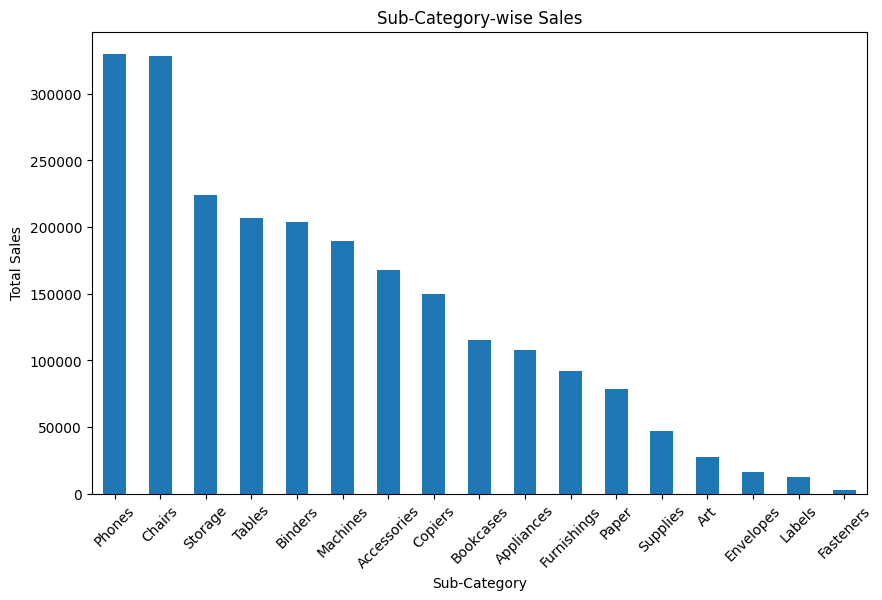

In [17]:
plt.figure(figsize=(10,6))

subcategory_sales.plot(kind="bar")

plt.title("Sub-Category-wise Sales")
plt.xlabel("Sub-Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [18]:
profit_category = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

print(profit_category)

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


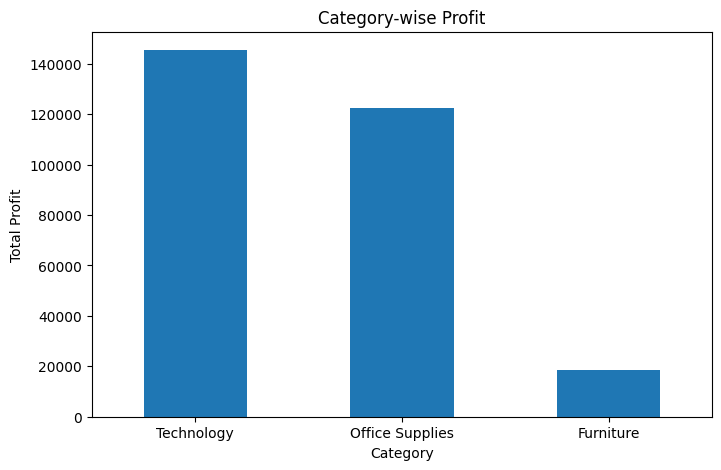

In [19]:
plt.figure(figsize=(8,5))

profit_category.plot(kind="bar")

plt.title("Category-wise Profit")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.show()

In [20]:
profit_subcategory = df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False)

print(profit_subcategory)

Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Chairs         26590.1663
Storage        21278.8264
Appliances     18138.0054
Furnishings    13059.1436
Envelopes       6964.1767
Art             6527.7870
Labels          5546.2540
Machines        3384.7569
Fasteners        949.5182
Supplies       -1189.0995
Bookcases      -3472.5560
Tables        -17725.4811
Name: Profit, dtype: float64


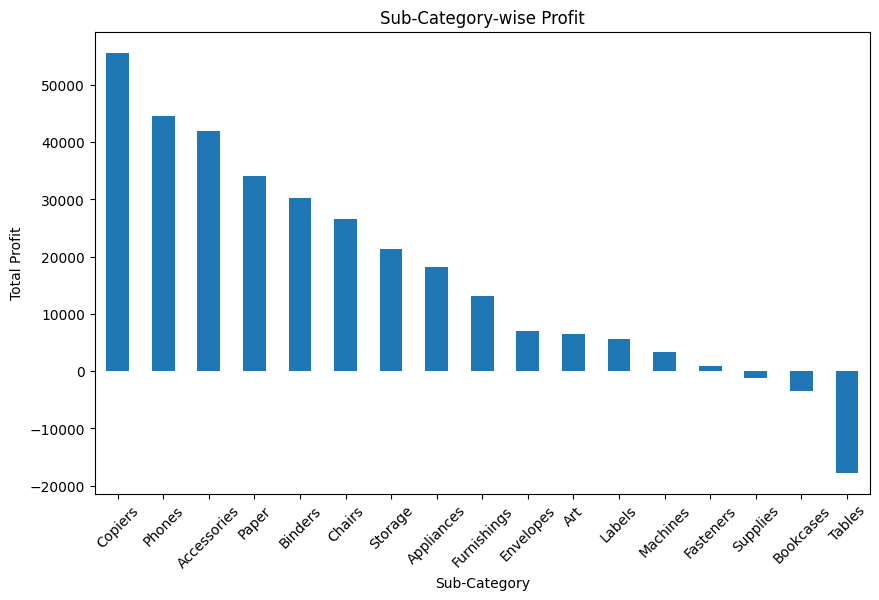

In [21]:
plt.figure(figsize=(10,6))

profit_subcategory.plot(kind="bar")

plt.title("Sub-Category-wise Profit")
plt.xlabel("Sub-Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.show()

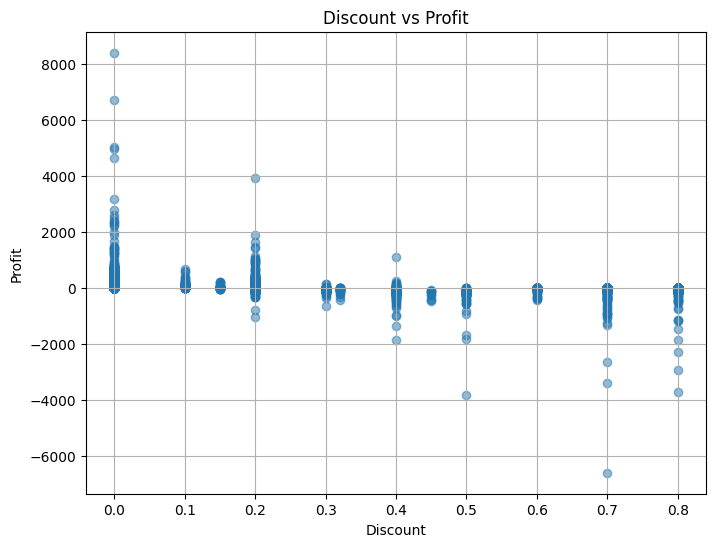

In [22]:
plt.figure(figsize=(8,6))

plt.scatter(df["Discount"], df["Profit"], alpha=0.5)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.grid(True)

plt.show()

In [23]:
discount_profit_corr = df["Discount"].corr(df["Profit"])

print("Correlation between Discount and Profit:", discount_profit_corr)

Correlation between Discount and Profit: -0.21948745637176803


Region-wise Sales:
Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


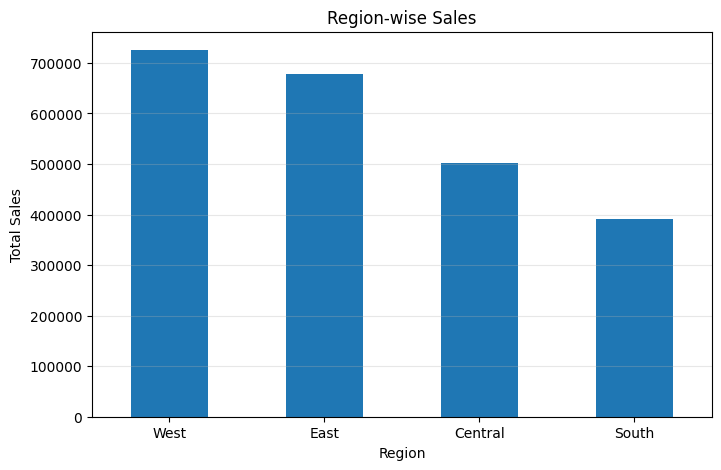

In [24]:
# Region-wise Sales Analysis

region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

print("Region-wise Sales:")
print(region_sales)

# Plot
plt.figure(figsize=(8,5))
region_sales.plot(kind="bar")

plt.title("Region-wise Sales")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

Region-wise Profit:
Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


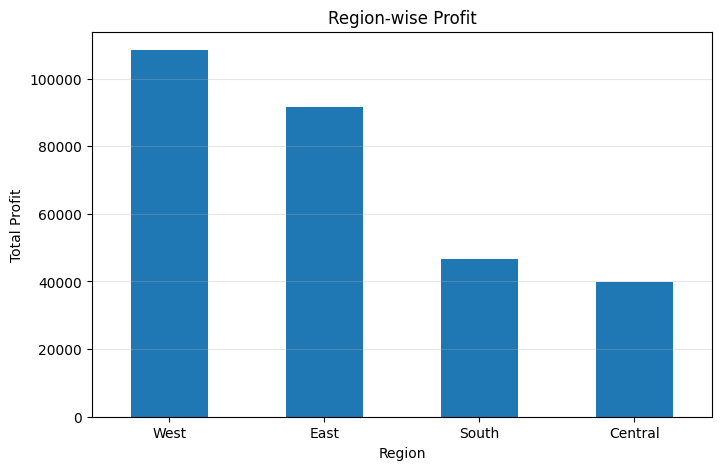

In [25]:
# Region-wise Profit Analysis

region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)

print("Region-wise Profit:")
print(region_profit)

# Plot
plt.figure(figsize=(8,5))
region_profit.plot(kind="bar")

plt.title("Region-wise Profit")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

Sales by Category and Region:


Region,Central,East,South,West
Category,,,,
Furniture,163797.1638,208291.204,117298.684,252612.7435
Office Supplies,167026.4150,205516.055,125651.313,220853.2490
Technology,170416.3120,264973.981,148771.908,251991.8320


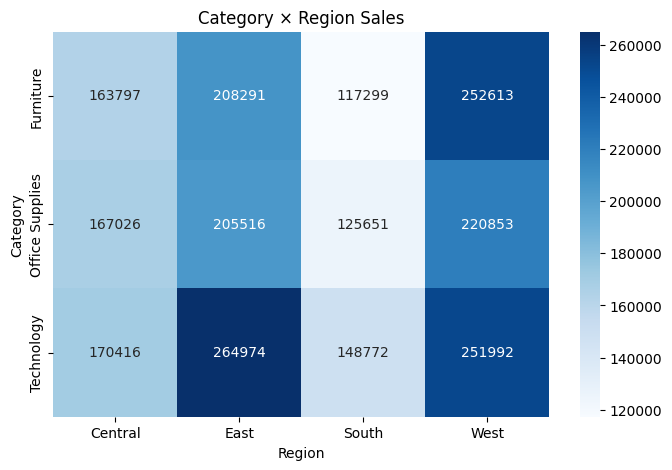

In [26]:
# Category-wise Sales by Region

category_region_sales = df.pivot_table(
    values="Sales",
    index="Category",
    columns="Region",
    aggfunc="sum"
)

print("Sales by Category and Region:")
display(category_region_sales)

# Heatmap
plt.figure(figsize=(8,5))
sns.heatmap(category_region_sales, annot=True, fmt=".0f", cmap="Blues")

plt.title("Category × Region Sales")
plt.xlabel("Region")
plt.ylabel("Category")
plt.show()

Profit by Category and Region:


Region,Central,East,South,West
Category,,,,
Furniture,-2871.0494,3046.1658,6771.2061,11504.9503
Office Supplies,8879.9799,41014.5791,19986.3928,52609.8490
Technology,33697.4320,47462.0351,19991.8314,44303.6496


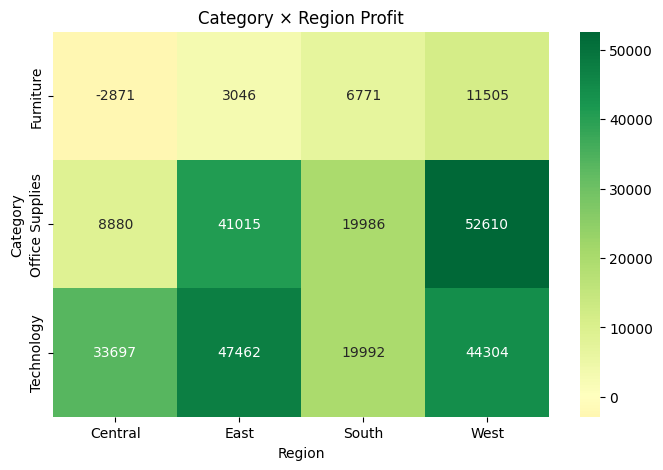

In [27]:
# Category × Region Profit Analysis

category_region_profit = df.pivot_table(
    values="Profit",
    index="Category",
    columns="Region",
    aggfunc="sum"
)

print("Profit by Category and Region:")
display(category_region_profit)

# Heatmap
plt.figure(figsize=(8,5))
sns.heatmap(category_region_profit, annot=True, fmt=".0f", cmap="RdYlGn", center=0)

plt.title("Category × Region Profit")
plt.xlabel("Region")
plt.ylabel("Category")
plt.show()

Top 10 Products by Sales:


,Sales
Product Name,
Canon imageCLASS 2200 Advanced Copier,61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480
HON 5400 Series Task Chairs for Big and Tall,21870.576
GBC DocuBind TL300 Electric Binding System,19823.479
GBC Ibimaster 500 Manual ProClick Binding System,19024.500
Hewlett Packard LaserJet 3310 Copier,18839.686
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895
GBC DocuBind P400 Electric Binding System,17965.068


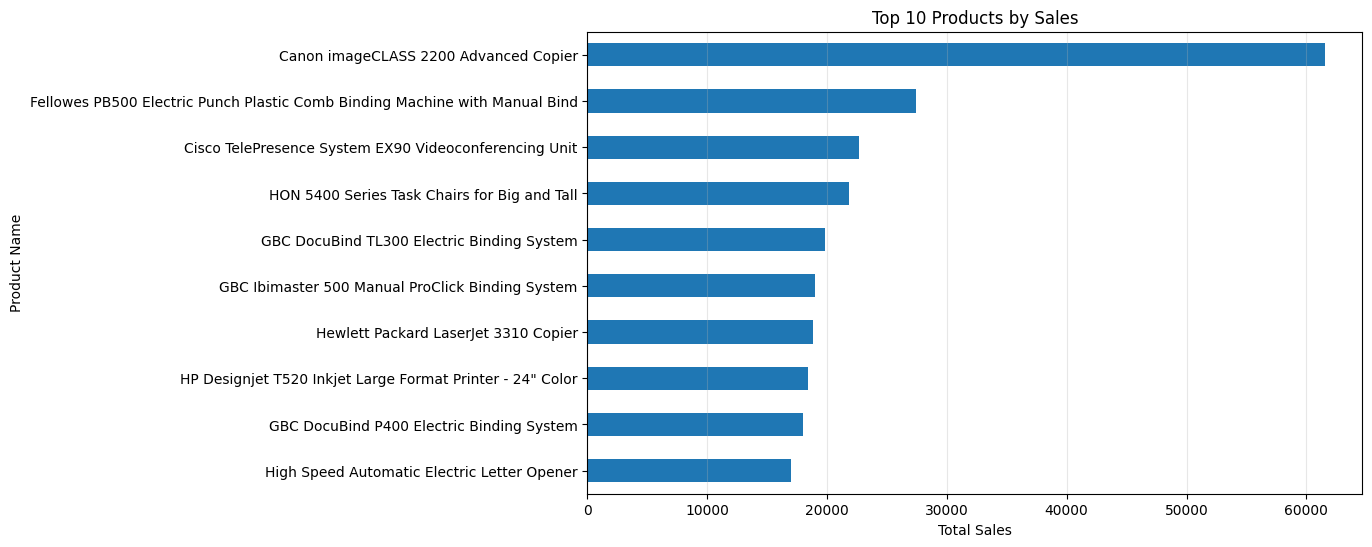

In [28]:
# Top 10 Products by Sales

top_products_sales = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Sales:")
display(top_products_sales)

# Plot
plt.figure(figsize=(10,6))
top_products_sales.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.grid(axis="x", alpha=0.3)
plt.show()

Top 10 Products by Profit:


,Profit
Product Name,
Canon imageCLASS 2200 Advanced Copier,25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,7753.0390
Hewlett Packard LaserJet 3310 Copier,6983.8836
Canon PC1060 Personal Laser Copier,4570.9347
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",4094.9766
Ativa V4110MDD Micro-Cut Shredder,3772.9461
"3D Systems Cube Printer, 2nd Generation, Magenta",3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System,3696.2820
Ibico EPK-21 Electric Binding System,3345.2823


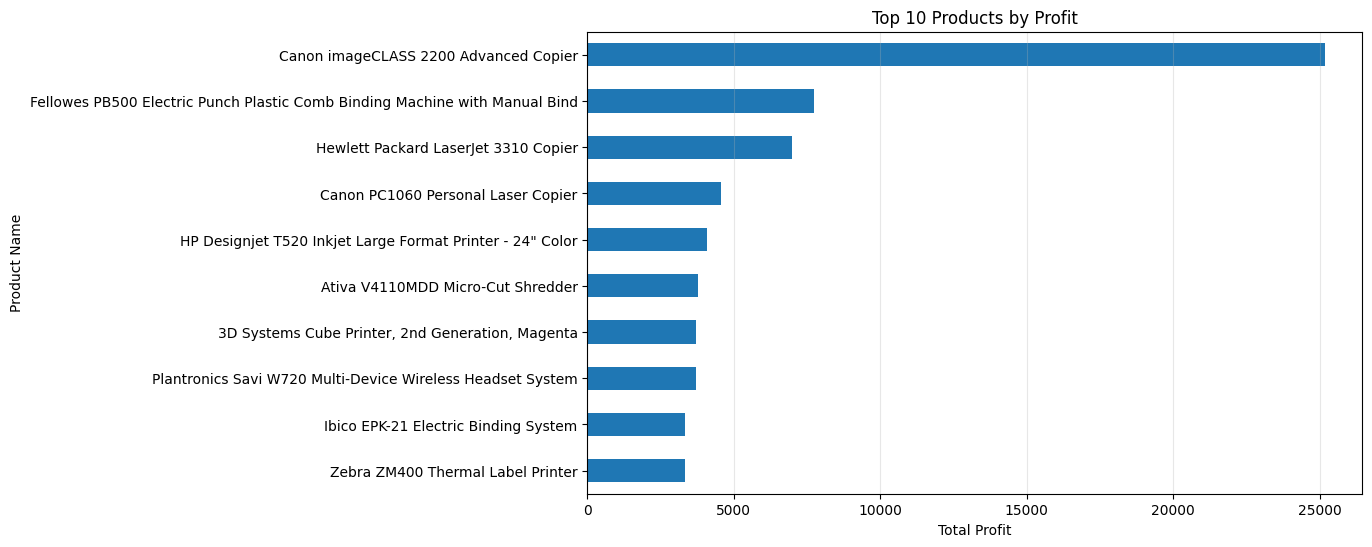

In [29]:
# Top 10 Products by Profit

top_products_profit = (
    df.groupby("Product Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Profit:")
display(top_products_profit)

# Plot
plt.figure(figsize=(10,6))
top_products_profit.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Product Name")
plt.grid(axis="x", alpha=0.3)
plt.show()

Sales by Segment:


,Sales
Segment,
Consumer,1.161401e+06
Corporate,7.061464e+05
Home Office,4.296531e+05


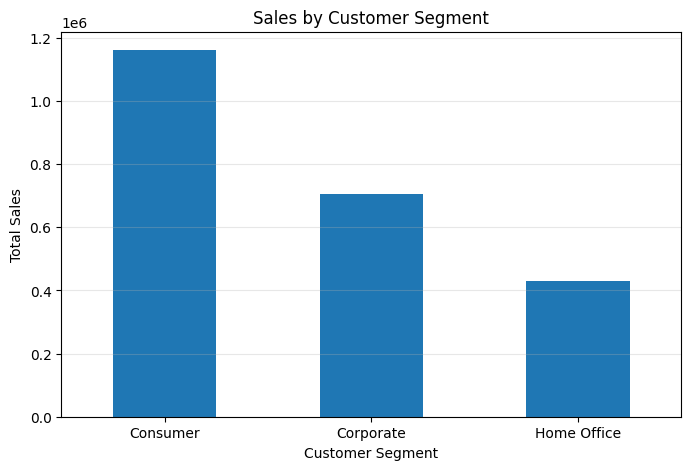

In [30]:
# Sales by Customer Segment

segment_sales = (
    df.groupby("Segment")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Segment:")
display(segment_sales)

plt.figure(figsize=(8,5))
segment_sales.plot(kind="bar")

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

Profit by Segment:


,Profit
Segment,
Consumer,134119.2092
Corporate,91979.1340
Home Office,60298.6785


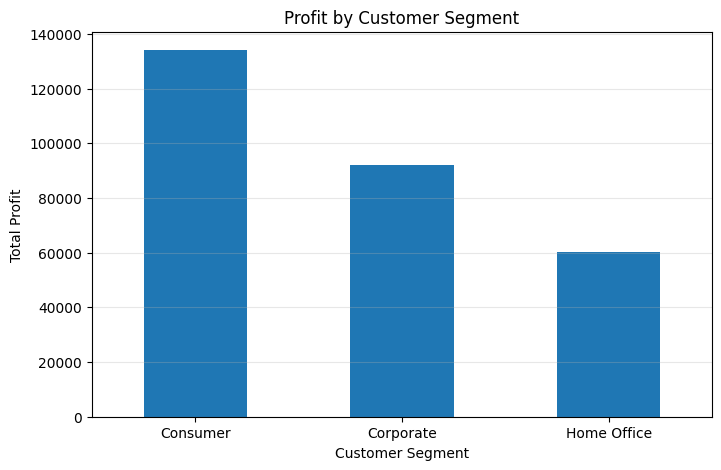

In [31]:
# Profit by Customer Segment

segment_profit = (
    df.groupby("Segment")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print("Profit by Segment:")
display(segment_profit)

plt.figure(figsize=(8,5))
segment_profit.plot(kind="bar")

plt.title("Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [32]:
# Calculate shipping duration

df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print(df["Shipping Days"].describe())

count    9994.000000
mean        3.958175
std         1.747567
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Shipping Days, dtype: float64


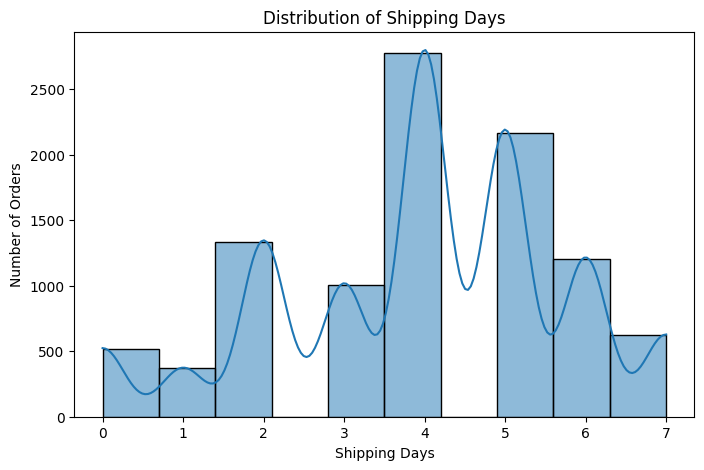

In [33]:
plt.figure(figsize=(8,5))

sns.histplot(df["Shipping Days"], bins=10, kde=True)

plt.title("Distribution of Shipping Days")
plt.xlabel("Shipping Days")
plt.ylabel("Number of Orders")

plt.show()

In [34]:
print("Average Shipping Time:", df["Shipping Days"].mean(), "days")
print("Fastest Shipping:", df["Shipping Days"].min(), "days")
print("Longest Shipping:", df["Shipping Days"].max(), "days")

Average Shipping Time: 3.958174904942966 days
Fastest Shipping: 0 days
Longest Shipping: 7 days


In [35]:
# Business KPI Summary

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["Product ID"].nunique()
avg_shipping_days = df["Shipping Days"].mean()
profit_margin = (total_profit / total_sales) * 100

print("========== BUSINESS KPI SUMMARY ==========")
print(f"Total Sales       : ${total_sales:,.2f}")
print(f"Total Profit      : ${total_profit:,.2f}")
print(f"Profit Margin     : {profit_margin:.2f}%")
print(f"Total Quantity    : {total_quantity:,}")
print(f"Total Orders      : {total_orders:,}")
print(f"Total Customers   : {total_customers:,}")
print(f"Total Products    : {total_products:,}")
print(f"Avg Shipping Time : {avg_shipping_days:.2f} days")

========== BUSINESS KPI SUMMARY ==========
Total Sales       : $2,297,200.86
Total Profit      : $286,397.02
Profit Margin     : 12.47%
Total Quantity    : 37,873
Total Orders      : 5,009
Total Customers   : 793
Total Products    : 1,862
Avg Shipping Time : 3.96 days


Year-wise Sales and Profit:


,Sales,Profit
Year,,
2014,484247.4981,49543.9741
2015,470532.5090,61618.6037
2016,609205.5980,81795.1743
2017,733215.2552,93439.2696


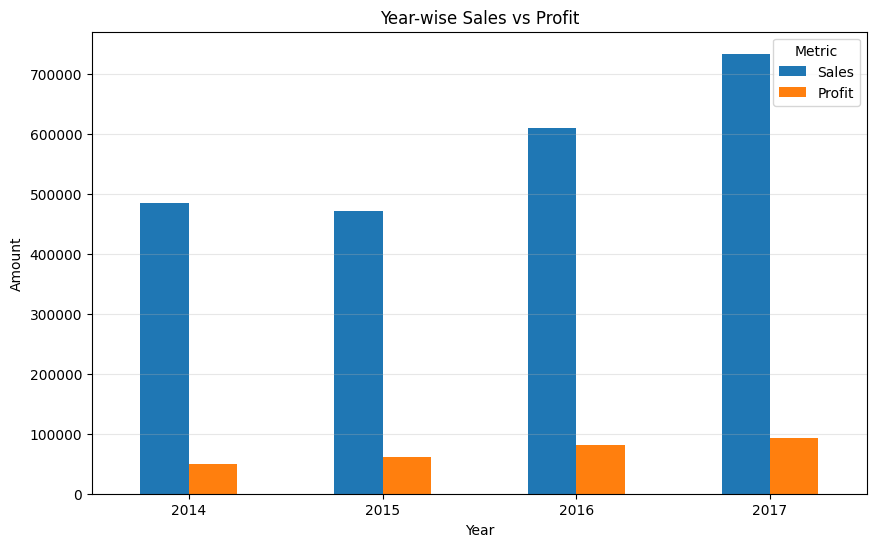

In [36]:
# Year-wise Sales vs Profit

year_performance = df.groupby("Year")[["Sales", "Profit"]].sum()

print("Year-wise Sales and Profit:")
display(year_performance)

# Plot
year_performance.plot(kind="bar", figsize=(10,6))

plt.title("Year-wise Sales vs Profit")
plt.xlabel("Year")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [37]:
# Loss-Making Products

product_profit = (
    df.groupby("Product Name")["Profit"]
    .sum()
    .sort_values()
)

loss_products = product_profit[product_profit < 0]

print("Number of Loss-Making Products:", len(loss_products))

print("\nTop 10 Loss-Making Products:")
display(loss_products.head(10))

Number of Loss-Making Products: 301

Top 10 Loss-Making Products:


,Profit
Product Name,
Cubify CubeX 3D Printer Double Head Print,-8879.9704
Lexmark MX611dhe Monochrome Laser Printer,-4589.9730
Cubify CubeX 3D Printer Triple Head Print,-3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,-2876.1156
Bush Advantage Collection Racetrack Conference Table,-1934.3976
GBC DocuBind P400 Electric Binding System,-1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit,-1811.0784
Martin Yale Chadless Opener Electric Letter Opener,-1299.1836
Balt Solid Wood Round Tables,-1201.0581


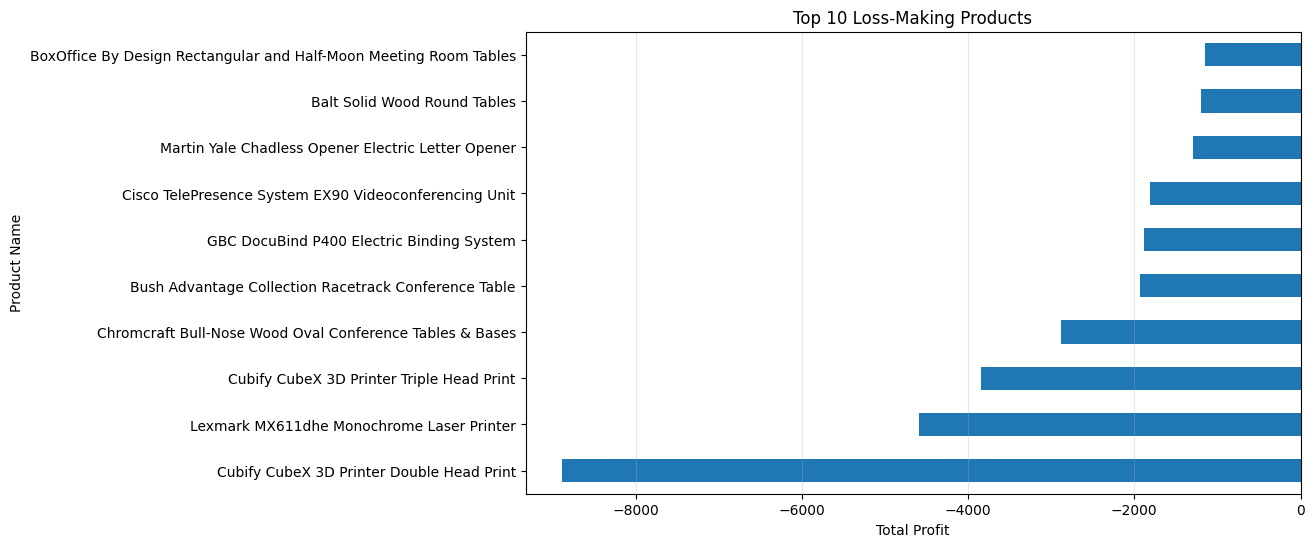

In [38]:
plt.figure(figsize=(10,6))

loss_products.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Loss-Making Products")
plt.xlabel("Total Profit")
plt.ylabel("Product Name")
plt.grid(axis="x", alpha=0.3)

plt.show()

Top 10 Customers by Sales:
Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64


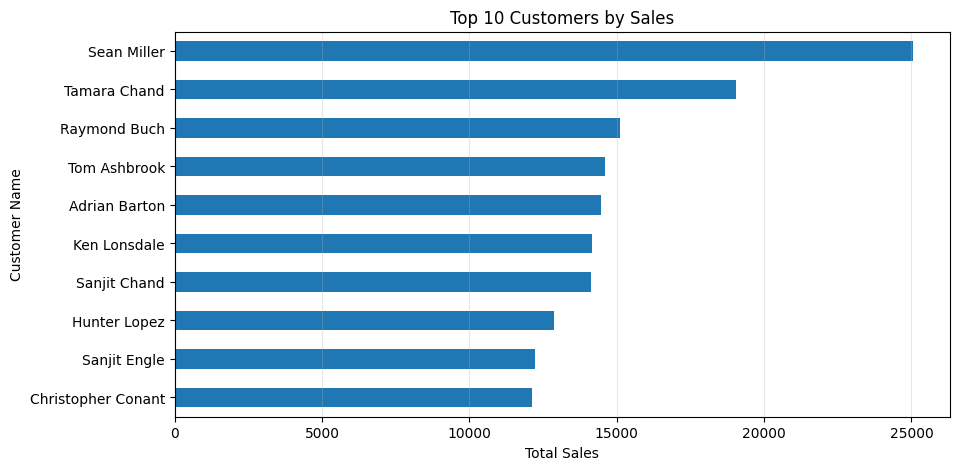

In [39]:
# Customer-wise Sales Analysis

customer_sales = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False)

print("Top 10 Customers by Sales:")
print(customer_sales.head(10))

# Plot
plt.figure(figsize=(10,5))
customer_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")
plt.grid(axis="x", alpha=0.3)
plt.show()

Top 10 Customers by Profit:
Customer Name
Tamara Chand            8981.3239
Raymond Buch            6976.0959
Sanjit Chand            5757.4119
Hunter Lopez            5622.4292
Adrian Barton           5444.8055
Tom Ashbrook            4703.7883
Christopher Martinez    3899.8904
Keith Dawkins           3038.6254
Andy Reiter             2884.6208
Daniel Raglin           2869.0760
Name: Profit, dtype: float64


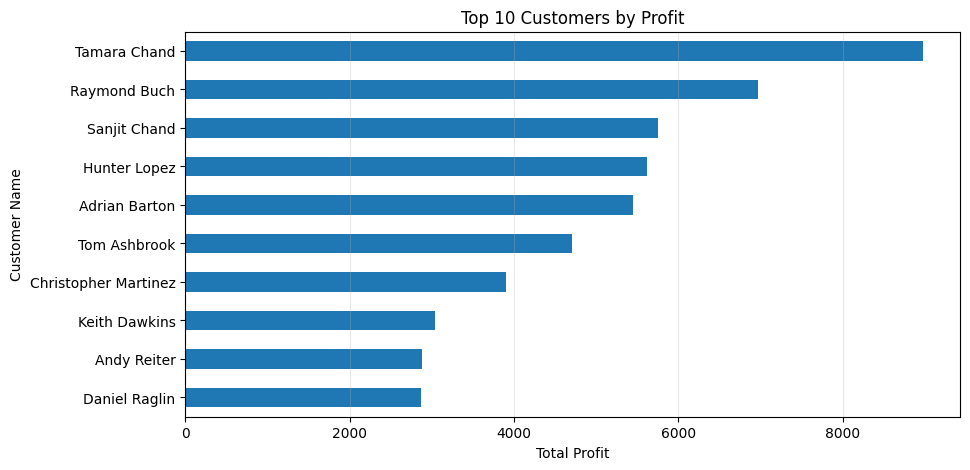

In [40]:
# Customer-wise Profit Analysis

customer_profit = df.groupby("Customer Name")["Profit"].sum().sort_values(ascending=False)

print("Top 10 Customers by Profit:")
print(customer_profit.head(10))

# Plot
plt.figure(figsize=(10,5))
customer_profit.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Customer Name")
plt.grid(axis="x", alpha=0.3)
plt.show()

Top 10 Products by Sales:
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


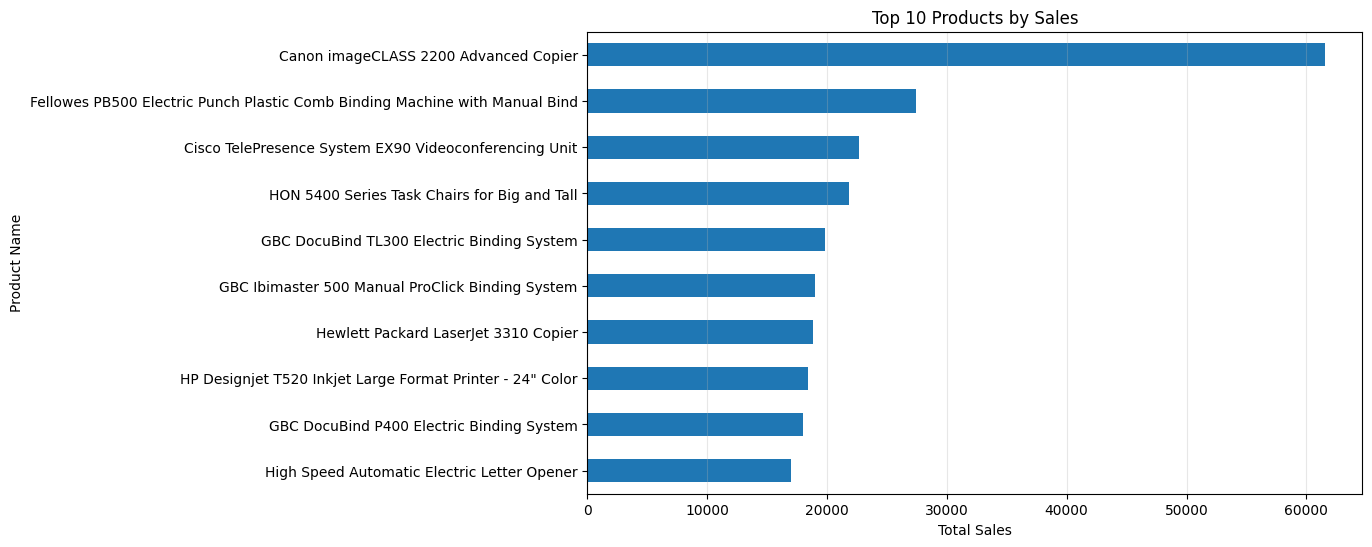

In [41]:
# Product-wise Sales Analysis

product_sales = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False)

print("Top 10 Products by Sales:")
print(product_sales.head(10))

# Plot
plt.figure(figsize=(10,6))
product_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.grid(axis="x", alpha=0.3)
plt.show()